In [1]:
# ============================================================
# 1. Imports
# ============================================================

import os

os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
os.environ["PYTORCH_MPS_HIGH_WATERMARK_RATIO"] = "0.0"

import glob
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn

# ============================================================
# 2. Dataset path
# ============================================================

DATA_PATH = "./GEFCom2014-L_V2/Load"


tasks = sorted(
    glob.glob(DATA_PATH + "/Task */L*-train.csv")
)

print("Number of tasks:", len(tasks))

Number of tasks: 15


In [2]:
from pathlib import Path
import re
import numpy as np
import pandas as pd

DATA_PATH = Path("./GEFCom2014-L_V2/Load")
weather_cols = [f"w{i}" for i in range(1, 26)]


def task_number(path):
    match = re.fullmatch(r"L(\d+)-train", path.stem)
    if match is None:
        raise ValueError(f"Unexpected filename: {path.name}")
    return int(match.group(1))


def parse_task_timestamps(raw, number):
    """
    For the supplied GEFCom2014 archive.

    Raw dates have no separators or zero padding, so individual
    strings can be ambiguous. Reconstruct each task's hourly
    sequence and validate EVERY timestamp against the raw string.
    """
    if number == 1:
        start = pd.Timestamp("2001-01-01 01:00:00")
    else:
        start = (
            pd.Timestamp("2010-10-01 01:00:00")
            + pd.DateOffset(months=number - 2)
        )

    timestamps = pd.date_range(
        start=start,
        periods=len(raw),
        freq="h",
    )

    expected = [
        f"{t.month}{t.day}{t.year} {t.hour}:00"
        for t in timestamps
    ]
    actual = raw.astype(str).str.strip().tolist()

    for row, (observed, required) in enumerate(zip(actual, expected)):
        if observed != required:
            raise ValueError(
                f"Task {number}, row {row}: "
                f"raw timestamp {observed!r} does not match "
                f"expected {required!r}. Check the source file."
            )

    return timestamps


tasks = sorted(
    DATA_PATH.glob("Task */L*-train.csv"),
    key=task_number,
)

if [task_number(p) for p in tasks] != list(range(1, 16)):
    raise ValueError(
        "Expected training files for Tasks 1–15. Check DATA_PATH."
    )

all_data = []

for file in tasks:
    temp = pd.read_csv(file)
    temp["TIMESTAMP"] = parse_task_timestamps(
        temp["TIMESTAMP"],
        task_number(file),
    )
    all_data.append(temp)

df = (
    pd.concat(all_data, ignore_index=True)
    .sort_values(["ZONEID", "TIMESTAMP"])
    .reset_index(drop=True)
)

if df.duplicated(["ZONEID", "TIMESTAMP"]).any():
    raise ValueError("Unexpected duplicate zone/timestamp pairs.")

if df["ZONEID"].nunique() != 1:
    raise ValueError("This pipeline expects one zone.")

# The supplied archive has an initial weather-only period.
# Remove it; no resampling or interpolation is needed.
df_hourly = (
    df.loc[
        df["LOAD"].notna(),
        ["TIMESTAMP", "LOAD"] + weather_cols,
    ]
    .reset_index(drop=True)
)

assert len(df_hourly) == 60600
assert df_hourly[["LOAD"] + weather_cols].notna().all().all()

hourly_steps = df_hourly["TIMESTAMP"].diff().iloc[1:]
assert hourly_steps.eq(pd.Timedelta(hours=1)).all()

print("Raw rows:", len(df))
print("Labelled rows:", len(df_hourly))
print("Start:", df_hourly["TIMESTAMP"].iloc[0])
print("End:", df_hourly["TIMESTAMP"].iloc[-1])
print("Non-hourly gaps:", (~hourly_steps.eq(pd.Timedelta(hours=1))).sum())

Raw rows: 95664
Labelled rows: 60600
Start: 2005-01-01 01:00:00
End: 2011-12-01 00:00:00
Non-hourly gaps: 0


In [3]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

HISTORY = 168
HORIZON = 24

df_hourly = (
    df_hourly
    .sort_values("TIMESTAMP")
    .reset_index(drop=True)
    .copy()
)

df_hourly["TIMESTAMP"] = pd.to_datetime(df_hourly["TIMESTAMP"])

# --------------------------------------------------
# 1. Calendar features — create BEFORE splitting
# --------------------------------------------------

hour = df_hourly["TIMESTAMP"].dt.hour
dow = df_hourly["TIMESTAMP"].dt.dayofweek
month = df_hourly["TIMESTAMP"].dt.month

df_hourly["hour_sin"] = np.sin(2 * np.pi * hour / 24)
df_hourly["hour_cos"] = np.cos(2 * np.pi * hour / 24)

df_hourly["dow_sin"] = np.sin(2 * np.pi * dow / 7)
df_hourly["dow_cos"] = np.cos(2 * np.pi * dow / 7)

df_hourly["month_sin"] = np.sin(2 * np.pi * month / 12)
df_hourly["month_cos"] = np.cos(2 * np.pi * month / 12)

calendar_cols = [
    "hour_sin",
    "hour_cos",
    "dow_sin",
    "dow_cos",
    "month_sin",
    "month_cos",
]

weather_cols = [f"w{i}" for i in range(1, 26)]

# --------------------------------------------------
# 2. Chronological splits
# Validation/test include past context only.
# Their targets start at the intended boundaries.
# --------------------------------------------------

n = len(df_hourly)

train_end = int(0.70 * n)
val_end = int(0.85 * n)

train_df = df_hourly.iloc[:train_end].copy()
val_df = df_hourly.iloc[train_end - HISTORY:val_end].copy()
test_df = df_hourly.iloc[val_end - HISTORY:].copy()

# --------------------------------------------------
# 3. Fit scalers ONLY on training data
# --------------------------------------------------

load_scaler = StandardScaler()
weather_scaler = StandardScaler()

load_scaler.fit(train_df[["LOAD"]])
weather_scaler.fit(train_df[weather_cols])

scaled_weather_cols = [f"{c}_scaled" for c in weather_cols]

for split in (train_df, val_df, test_df):
    split["LOAD_scaled"] = load_scaler.transform(
        split[["LOAD"]]
    ).ravel()

    split[scaled_weather_cols] = weather_scaler.transform(
        split[weather_cols]
    )

# --------------------------------------------------
# 4. Validate all required dataset inputs
# --------------------------------------------------

required_cols = (
    ["LOAD_scaled"]
    + scaled_weather_cols
    + calendar_cols
)

for name, split in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    missing = [c for c in required_cols if c not in split.columns]
    assert not missing, f"{name}: missing columns {missing}"

    assert np.isfinite(
        split[required_cols].to_numpy(dtype=np.float64)
    ).all(), f"{name}: NaN or infinite input values"

    assert len(split) >= HISTORY + HORIZON

    print(
        f"{name}: {len(split):,} rows | "
        f"{len(split) - HISTORY - HORIZON + 1:,} windows"
    )

assert (
    val_df["TIMESTAMP"].iloc[HISTORY]
    == df_hourly["TIMESTAMP"].iloc[train_end]
)

assert (
    test_df["TIMESTAMP"].iloc[HISTORY]
    == df_hourly["TIMESTAMP"].iloc[val_end]
)

print("Calendar features, splits, and scaling are ready.")

Train: 42,420 rows | 42,229 windows
Validation: 9,258 rows | 9,067 windows
Test: 9,258 rows | 9,067 windows
Calendar features, splits, and scaling are ready.


In [4]:
class EnergyDataset(torch.utils.data.Dataset):

    def __init__(
        self,
        df,
        history=168,
        horizon=24
    ):

        self.history = history
        self.horizon = horizon


        # Past demand
        self.demand = (
            df["LOAD_scaled"]
            .values
            .astype(np.float32)
        )


        # Weather
        weather_cols = [
            f"w{i}_scaled"
            for i in range(1,26)
        ]


        self.weather = (
            df[weather_cols]
            .values
            .astype(np.float32)
        )


        # Calendar
        calendar_cols = [
            "hour_sin",
            "hour_cos",
            "dow_sin",
            "dow_cos",
            "month_sin",
            "month_cos"
        ]


        self.calendar = (
            df[calendar_cols]
            .values
            .astype(np.float32)
        )


    def __len__(self):
        return max(
            0,
            len(self.demand) - self.history - self.horizon + 1
        )


    def __getitem__(self, idx):

        start = idx
        end = idx + self.history

        target_start = end
        target_end = end + self.horizon


        # past inputs

        past_demand = self.demand[
            start:end
        ]

        past_weather = self.weather[
            start:end
        ]

        past_calendar = self.calendar[
            start:end
        ]


        # future known variables

        future_weather = self.weather[
            target_start:target_end
        ]

        future_calendar = self.calendar[
            target_start:target_end
        ]


        # previous day load pattern
        # last 24 hours before forecast

        last_day = self.demand[
            end-24:end
        ]


        # target

        target = self.demand[
            target_start:target_end
        ]


        return {

            "past_demand": torch.tensor(
                past_demand,
                dtype=torch.float32
            ).unsqueeze(-1),


            "past_weather": torch.tensor(
                past_weather,
                dtype=torch.float32
            ),


            "past_calendar": torch.tensor(
                past_calendar,
                dtype=torch.float32
            ),


            "future_weather": torch.tensor(
                future_weather,
                dtype=torch.float32
            ),


            "future_calendar": torch.tensor(
                future_calendar,
                dtype=torch.float32
            ),


            "last_day": torch.tensor(
                last_day,
                dtype=torch.float32
            ),


            "target": torch.tensor(
                target,
                dtype=torch.float32
            )

        }

In [5]:
train_dataset = EnergyDataset(
    train_df,
    history=168,
    horizon=24
)


val_dataset = EnergyDataset(
    val_df,
    history=168,
    horizon=24
)


test_dataset = EnergyDataset(
    test_df,
    history=168,
    horizon=24
)

In [6]:
import torch 
from torch.utils.data import DataLoader

train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0
)


val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)


test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0
)

In [7]:
class DomainEncoder(nn.Module):

    def __init__(
        self,
        input_dim,
        d_model=32
    ):
        super().__init__()


        self.projection = nn.Linear(
            input_dim,
            d_model
        )


        self.norm = nn.LayerNorm(
            d_model
        )


    def forward(self,x):

        # x:
        # batch, time, features

        x = self.projection(x)

        x = self.norm(x)

        return x

In [8]:
class PositionalEncoding(nn.Module):

    def __init__(
        self,
        d_model,
        max_len=500
    ):

        super().__init__()


        pe = torch.zeros(
            max_len,
            d_model
        )


        position = torch.arange(
            0,
            max_len
        ).unsqueeze(1)


        div_term = torch.exp(
            torch.arange(
                0,
                d_model,
                2
            )
            *
            (-np.log(10000.0)/d_model)
        )


        pe[:,0::2] = torch.sin(
            position*div_term
        )


        pe[:,1::2] = torch.cos(
            position*div_term
        )


        self.register_buffer(
            "pe",
            pe.unsqueeze(0)
        )


    def forward(self,x):

        return x + self.pe[:,:x.size(1)]

In [9]:
class DomainFusion(nn.Module):

    def __init__(
        self,
        d_model=64,
        heads=4
    ):

        super().__init__()


        # weather and calendar gates

        self.weather_gate = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.Sigmoid()
        )


        self.calendar_gate = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.Sigmoid()
        )


        self.attention = nn.MultiheadAttention(
            d_model,
            heads,
            batch_first=True
        )


        self.norm = nn.LayerNorm(
            d_model
        )


        self.dropout = nn.Dropout(0.1)



    def forward(
        self,
        demand,
        weather,
        calendar
    ):


        w_gate = self.weather_gate(
            weather
        )


        c_gate = self.calendar_gate(
            calendar
        )


        # demand is preserved

        x = (
            demand
            +
            w_gate * weather
            +
            c_gate * calendar
        )


        attn,_ = self.attention(
            x,
            x,
            x
        )


        x = self.norm(
            x+self.dropout(attn)
        )


        return x

In [10]:
import math
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt


class OrderedQuantileHead(nn.Module):
    """
    Input:  [batch, horizon, d_model]
    Output: [batch, horizon, 99]

    Quantiles: 0.01, 0.02, ..., 0.99
    Median index: 49

    Positive increments enforce non-crossing quantiles.
    """

    def __init__(self, input_dim):
        super().__init__()

        self.hidden = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.GELU(),
        )
        self.output = nn.Linear(128, 99)

        # Initially small corrections to the previous-day baseline.
        nn.init.normal_(self.output.weight, std=0.005)

        with torch.no_grad():
            self.output.bias.zero_()

            # Initial adjacent quantile spacing in standardized units.
            initial_spacing = 0.02
            inverse_softplus = math.log(math.expm1(initial_spacing))
            self.output.bias[1:].fill_(inverse_softplus)

    def forward(self, x):
        raw = self.output(self.hidden(x))

        median = raw[..., :1]

        # 49 increments on either side of the median.
        lower_steps = F.softplus(raw[..., 1:50])
        upper_steps = F.softplus(raw[..., 50:99])

        lower = median - torch.cumsum(
            lower_steps, dim=-1
        ).flip(-1)

        upper = median + torch.cumsum(
            upper_steps, dim=-1
        )

        return torch.cat(
            [lower, median, upper],
            dim=-1,
        )


class DreamFormerV5(nn.Module):

    def __init__(self, d_model=64, horizon=24):
        super().__init__()

        if horizon != 24:
            raise ValueError(
                "The current last-day dataset requires horizon=24."
            )

        self.register_buffer(
            "taus",
            torch.arange(1, 100).float() / 100,
        )

        self.demand_encoder = DomainEncoder(1, d_model)
        self.weather_encoder = DomainEncoder(25, d_model)
        self.calendar_encoder = DomainEncoder(6, d_model)

        self.future_weather_encoder = DomainEncoder(25, d_model)
        self.future_calendar_encoder = DomainEncoder(6, d_model)

        self.position = PositionalEncoding(d_model)
        self.fusion = DomainFusion(d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=4,
            dim_feedforward=256,
            dropout=0.1,
            activation="gelu",
            batch_first=True,
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2,
        )

        self.query = nn.Parameter(
            torch.randn(horizon, d_model)
        )

        self.future_fusion = nn.Linear(
            2 * d_model,
            d_model,
        )
        self.future_norm = nn.LayerNorm(d_model)

        self.head = OrderedQuantileHead(d_model)

    def forward(
        self,
        past_demand,
        past_weather,
        past_calendar,
        future_weather,
        future_calendar,
        last_day,
    ):
        # Historical encoders and fusion: same structure as v4.
        d = self.position(self.demand_encoder(past_demand))
        w = self.position(self.weather_encoder(past_weather))
        c = self.position(self.calendar_encoder(past_calendar))

        history = self.transformer(
            self.fusion(d, w, c)
        )

        # Horizon-specific retrieval: same structure as v4.
        queries = self.query.unsqueeze(0).expand(
            history.size(0), -1, -1
        )

        attention = torch.softmax(
            queries @ history.transpose(1, 2)
            / math.sqrt(history.size(-1)),
            dim=-1,
        )

        context = attention @ history

        # Future weather and calendar inputs.
        future = self.future_fusion(
            torch.cat(
                [
                    self.future_weather_encoder(future_weather),
                    self.future_calendar_encoder(future_calendar),
                ],
                dim=-1,
            )
        )

        z = self.future_norm(context + future)

        # Add the same previous-day baseline to every quantile.
        # Output: [batch, 24, 99]
        return last_day.unsqueeze(-1) + self.head(z)


def pinball_loss(quantiles, target, taus):
    """
    quantiles: [batch, horizon, 99]
    target:    [batch, horizon]
    taus:      [99]
    """
    error = target.unsqueeze(-1) - quantiles

    return torch.maximum(
        taus * error,
        (taus - 1) * error,
    ).mean()


INPUT_KEYS = (
    "past_demand",
    "past_weather",
    "past_calendar",
    "future_weather",
    "future_calendar",
    "last_day",
)


def batch_inputs(batch, device):
    return [
        batch[key].to(device)
        for key in INPUT_KEYS
    ]

In [11]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

config = {
    "d_model": 64,
    "horizon": 24,
}

model = DreamFormerV5(**config).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
)

CHECKPOINT = Path(
    f"dreamformer_v5_quantile_seed{SEED}_best.pt"
)

EPOCHS = 30
PATIENCE = 8

# Check shapes and ordering before training.
model.eval()

with torch.no_grad():
    sample_batch = next(iter(val_loader))
    sample_q = model(
        *batch_inputs(sample_batch, device)
    )

assert sample_q.shape == (
    sample_batch["target"].shape[0],
    24,
    99,
)
assert torch.isfinite(sample_q).all().item()
assert (sample_q.diff(dim=-1) >= -1e-6).all().item()

print("Device:", device)
print("Quantile output:", tuple(sample_q.shape))
print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    ),
)

Device: mps
Quantile output: (64, 24, 99)
Trainable parameters: 161059


In [12]:
from tqdm.auto import tqdm
import time

def run_epoch(loader, training):
    model.train(training)

    total_loss = 0.0
    total_samples = 0

    progress = tqdm(
        loader,
        desc="Train" if training else "Validation",
        leave=False,
        dynamic_ncols=True,
    )

    with torch.set_grad_enabled(training):
        for batch in progress:
            target = batch["target"].to(device)

            if training:
                optimizer.zero_grad(set_to_none=True)

            quantiles = model(
                *batch_inputs(batch, device)
            )

            loss = pinball_loss(
                quantiles,
                target,
                model.taus,
            )

            if not torch.isfinite(loss).item():
                raise FloatingPointError(
                    "Non-finite pinball loss."
                )

            if training:
                loss.backward()

                nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0,
                )

                optimizer.step()

            batch_size = target.size(0)

            total_loss += loss.detach().item() * batch_size
            total_samples += batch_size

            progress.set_postfix(
                loss=f"{loss.item():.6f}"
            )

    if total_samples == 0:
        raise ValueError("Empty DataLoader.")

    return total_loss / total_samples



best_val = float("inf")
bad_epochs = 0
saved_this_run = False

history = {
    "train_pinball": [],
    "val_pinball": [],
}

for epoch in range(1, EPOCHS + 1):

    epoch_start = time.time()

    train_score = run_epoch(train_loader, training=True)
    val_score = run_epoch(val_loader, training=False)

    scheduler.step(val_score)

    history["train_pinball"].append(train_score)
    history["val_pinball"].append(val_score)

    current_lr = optimizer.param_groups[0]["lr"]

    saved_msg = ""

    if val_score < best_val:
        best_val = val_score
        bad_epochs = 0

        torch.save(
            {
                "epoch": epoch,
                "config": config,
                "seed": SEED,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "val_pinball": val_score,
                "load_mean": load_scaler.mean_.tolist(),
                "load_scale": load_scaler.scale_.tolist(),
                "weather_mean": weather_scaler.mean_.tolist(),
                "weather_scale": weather_scaler.scale_.tolist(),
            },
            CHECKPOINT,
        )

        saved_this_run = True
        saved_msg = f" ✓ Best model saved ({val_score:.6f})"

    else:
        bad_epochs += 1

        if bad_epochs >= PATIENCE:
            saved_msg = " | Early stopping triggered"

    epoch_time = time.time() - epoch_start

    print(
        "\n" + "=" * 70
    )

    print(
        f"Epoch [{epoch}/{EPOCHS}] "
        f"Train Loss : {train_score:.6f} "
        f"Val Loss   : {val_score:.6f} "
        f"Learning Rate : {current_lr:.8f} "
        f"Time : {epoch_time:.2f} sec"
        f"{saved_msg}"
    )

    if bad_epochs >= PATIENCE:
        break   

# Restore trained weights. Do not reinitialize the model here.
checkpoint = torch.load(
    CHECKPOINT,
    map_location=device,
    weights_only=True,
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True,
)

model.eval()

print("Restored epoch:", checkpoint["epoch"])
print("Best validation pinball:", checkpoint["val_pinball"])

/opt/anaconda3/envs/AI/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Train:   0%|          | 0/660 [00:00<?, ?it/s]


Epoch [1/30] Train Loss : 0.107526 Val Loss   : 0.097443 Learning Rate : 0.00010000 Time : 64.66 sec ✓ Best model saved (0.097443)



Epoch [2/30] Train Loss : 0.079435 Val Loss   : 0.079317 Learning Rate : 0.00010000 Time : 81.14 sec ✓ Best model saved (0.079317)



Epoch [3/30] Train Loss : 0.068124 Val Loss   : 0.073701 Learning Rate : 0.00010000 Time : 152.90 sec ✓ Best model saved (0.073701)



Epoch [4/30] Train Loss : 0.060725 Val Loss   : 0.066380 Learning Rate : 0.00010000 Time : 113.21 sec ✓ Best model saved (0.066380)



Epoch [5/30] Train Loss : 0.056236 Val Loss   : 0.060358 Learning Rate : 0.00010000 Time : 107.70 sec ✓ Best model saved (0.060358)


... (21 outputs left out)


Epoch [27/30] Train Loss : 0.035797 Val Loss   : 0.048365 Learning Rate : 0.00010000 Time : 65.29 sec



Epoch [28/30] Train Loss : 0.035410 Val Loss   : 0.048338 Learning Rate : 0.00010000 Time : 63.90 sec



Epoch [29/30] Train Loss : 0.035054 Val Loss   : 0.048363 Learning Rate : 0.00005000 Time : 64.53 sec



Epoch [30/30] Train Loss : 0.034172 Val Loss   : 0.048234 Learning Rate : 0.00005000 Time : 63.38 sec
Restored epoch: 25
Best validation pinball: 0.048018185572816424


In [16]:
from pathlib import Path
import torch

checkpoint_path = Path(
    "dreamformer_v5_quantile_seed42_best.pt"
).resolve()

print("Jupyter working directory:", Path.cwd())
print("Checkpoint location:", checkpoint_path)
print("File exists:", checkpoint_path.is_file())

if not checkpoint_path.is_file():
    raise FileNotFoundError(
        f"Checkpoint not found at {checkpoint_path}. "
        "Check whether the notebook's working directory changed."
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True,
)

model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True,
)

model.eval()

print("Loaded epoch:", checkpoint["epoch"])
print("Validation pinball:", checkpoint["val_pinball"])
print(
    "Checkpoint size:",
    f"{checkpoint_path.stat().st_size / (1024 ** 2):.2f} MB",
)

Jupyter working directory: /Users/pratyush/Coding/Projects/dreamformer
Checkpoint location: /Users/pratyush/Coding/Projects/dreamformer/dreamformer_v5_quantile_seed42_best.pt
File exists: True
Loaded epoch: 25
Validation pinball: 0.048018185572816424
Checkpoint size: 2.04 MB


In [17]:
@torch.no_grad()
def predict_v5(loader):
    model.eval()

    predictions = []
    targets = []

    for batch in loader:
        quantiles = model(
            *batch_inputs(batch, device)
        )

        predictions.append(
            quantiles.cpu().numpy()
        )
        targets.append(
            batch["target"].cpu().numpy()
        )

    return (
        np.concatenate(predictions, axis=0),
        np.concatenate(targets, axis=0),
    )


# Ensure the scalers correspond to this checkpoint.
assert np.allclose(
    load_scaler.mean_,
    checkpoint["load_mean"],
)
assert np.allclose(
    load_scaler.scale_,
    checkpoint["load_scale"],
)
assert np.allclose(
    weather_scaler.mean_,
    checkpoint["weather_mean"],
)
assert np.allclose(
    weather_scaler.scale_,
    checkpoint["weather_scale"],
)

q_scaled, y_scaled = predict_v5(test_loader)

# StandardScaler inverse transformation.
scale = float(load_scaler.scale_[0])
mean = float(load_scaler.mean_[0])

quantile_pred = q_scaled * scale + mean
y_true = y_scaled * scale + mean

taus = np.arange(1, 100) / 100.0

# [N, 24], compatible with your point-forecast plots.
pred = quantile_pred[..., 49]

errors = pred - y_true

mae = np.mean(np.abs(errors))
rmse = np.sqrt(np.mean(errors ** 2))

nonzero = np.abs(y_true) > 1e-8

mape = (
    100 * np.mean(
        np.abs(errors[nonzero] / y_true[nonzero])
    )
    if nonzero.any()
    else float("nan")
)

residual = y_true[..., None] - quantile_pred

mean_pinball = np.maximum(
    taus * residual,
    (taus - 1) * residual,
).mean()

crossing_rate = np.mean(
    np.diff(quantile_pred, axis=-1) < -1e-6
)

print("=" * 60)
print("Quantile predictions:", quantile_pred.shape)
print("Median predictions:", pred.shape)
print(f"Median MAE    : {mae:.4f}")
print(f"Median RMSE   : {rmse:.4f}")
print(f"Median MAPE   : {mape:.4f}%")
print(f"Mean pinball  : {mean_pinball:.4f}")
print(f"Crossing rate : {100 * crossing_rate:.6f}%")

for low, high in [(10, 90), (5, 95), (1, 99)]:
    lower = quantile_pred[..., low - 1]
    upper = quantile_pred[..., high - 1]

    coverage = np.mean(
        (y_true >= lower) & (y_true <= upper)
    )
    width = np.mean(upper - lower)

    print(
        f"{high - low}% interval | "
        f"Coverage: {100 * coverage:.2f}% | "
        f"Mean width: {width:.4f}"
    )

print("=" * 60)

horizon_metrics = pd.DataFrame(
    {
        "horizon": np.arange(1, y_true.shape[1] + 1),
        "MAE": np.abs(errors).mean(axis=0),
        "RMSE": np.sqrt((errors ** 2).mean(axis=0)),
        "bias": errors.mean(axis=0),
    }
)

print(horizon_metrics.to_string(index=False))

Quantile predictions: (9067, 24, 99)
Median predictions: (9067, 24)
Median MAE    : 7.2029
Median RMSE   : 11.4792
Median MAPE   : 5.9334%
Mean pinball  : 2.6889
Crossing rate : 0.000000%
80% interval | Coverage: 63.51% | Mean width: 14.8649
90% interval | Coverage: 75.93% | Mean width: 19.3765
98% interval | Coverage: 90.83% | Mean width: 29.2790
 horizon      MAE      RMSE     bias
       1 5.673800  9.227062 0.936277
       2 5.830082  9.504543 0.945935
       3 6.056476  9.768773 1.272222
       4 6.377149 10.252171 1.480002
       5 6.674259 10.666420 1.852609
       6 6.895563 11.002094 1.844692
       7 7.069512 11.149518 1.825951
       8 7.109386 11.383441 1.903472
       9 7.139097 11.463559 2.149008
      10 7.206044 11.621872 1.837855
      11 7.199892 11.623040 2.010457
      12 7.319489 11.710010 1.911816
      13 7.412010 11.791378 2.137151
      14 7.450766 11.879529 1.994205
      15 7.466578 11.839042 2.138038
      16 7.520651 11.926655 2.129118
      17 7.653824 12.

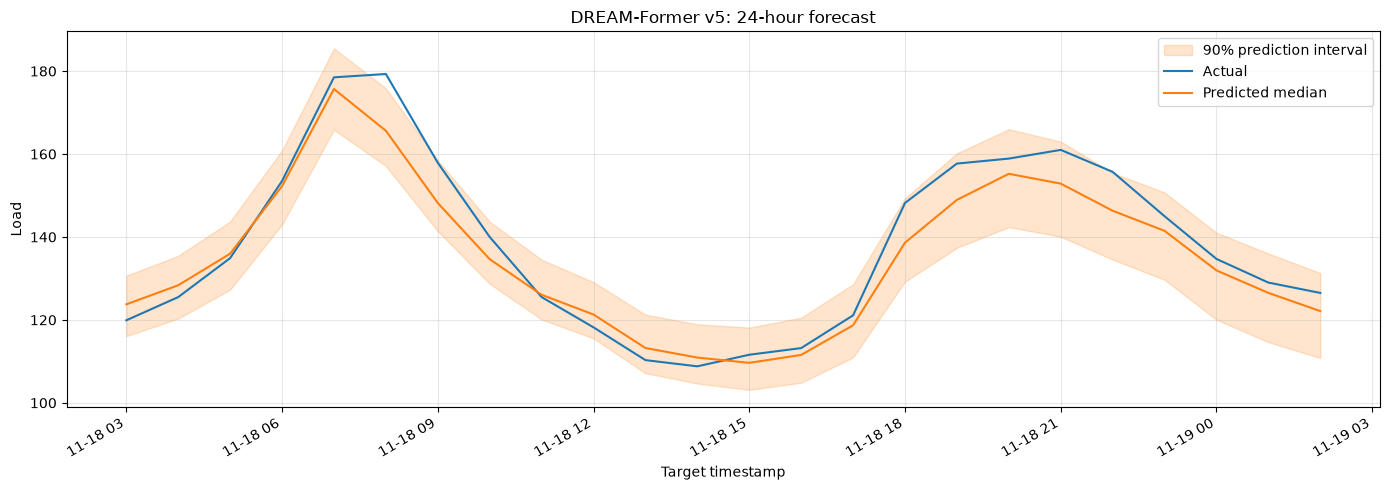

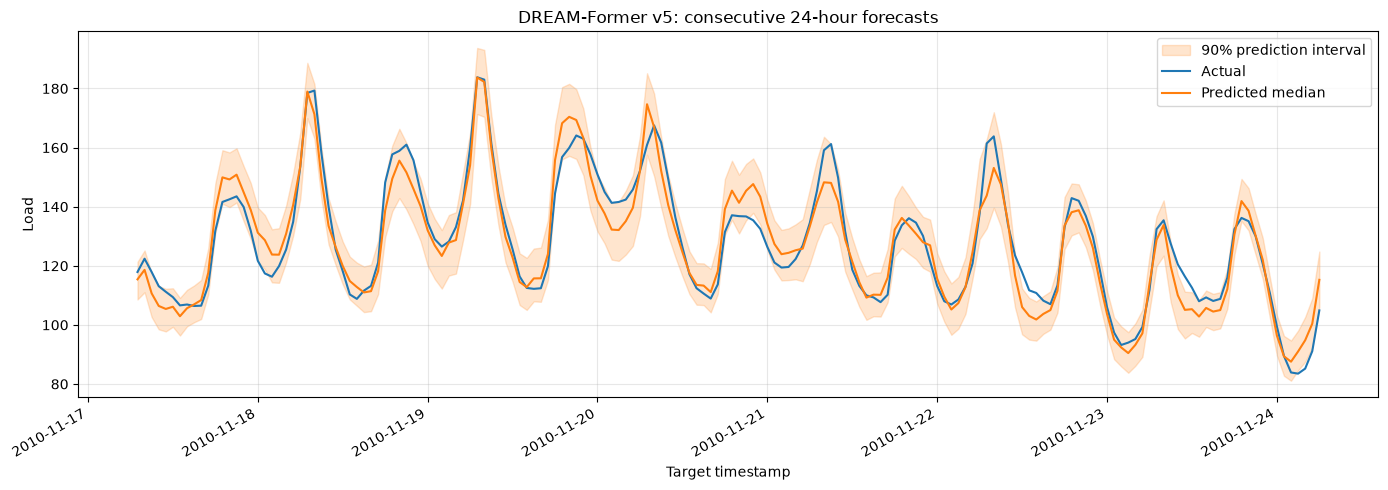

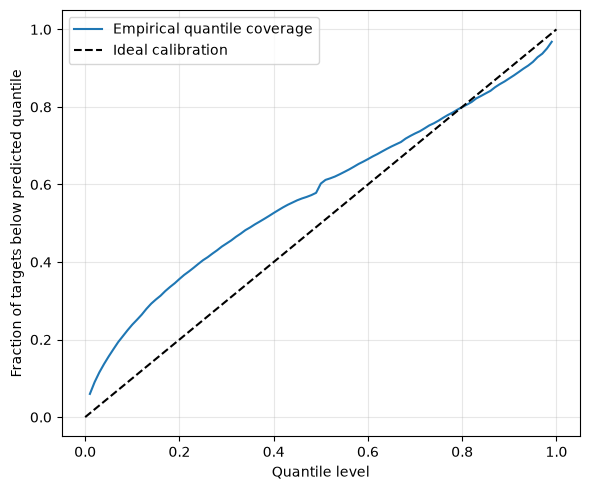

In [18]:
def plot_forecast(indices, title):
    indices = np.asarray(indices, dtype=int)

    positions = (
        indices[:, None]
        + test_dataset.history
        + np.arange(test_dataset.horizon)[None, :]
    )

    times = (
        test_df["TIMESTAMP"]
        .to_numpy()[positions]
        .reshape(-1)
    )

    observed = y_true[indices].reshape(-1)
    median = pred[indices].reshape(-1)

    # Central 90% prediction interval: Q0.05 to Q0.95.
    lower = quantile_pred[indices, :, 4].reshape(-1)
    upper = quantile_pred[indices, :, 94].reshape(-1)

    fig, ax = plt.subplots(figsize=(14, 5))

    ax.fill_between(
        times,
        lower,
        upper,
        alpha=0.20,
        color="tab:orange",
        label="90% prediction interval",
    )

    ax.plot(
        times,
        observed,
        color="tab:blue",
        label="Actual",
    )

    ax.plot(
        times,
        median,
        color="tab:orange",
        label="Predicted median",
    )

    ax.set(
        title=title,
        xlabel="Target timestamp",
        ylabel="Load",
    )

    ax.grid(alpha=0.3)
    ax.legend()

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()


plot_forecast(
    [min(20, len(pred) - 1)],
    "DREAM-Former v5: 24-hour forecast",
)

daily_indices = [
    i
    for i in range(0, 7 * 24, 24)
    if i < len(pred)
]

plot_forecast(
    daily_indices,
    "DREAM-Former v5: consecutive 24-hour forecasts",
)

# Calibration: empirical coverage should follow the diagonal.
empirical_coverage = (
    y_true[..., None] <= quantile_pred
).mean(axis=(0, 1))

plt.figure(figsize=(6, 5))

plt.plot(
    taus,
    empirical_coverage,
    label="Empirical quantile coverage",
)

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Ideal calibration",
)

plt.xlabel("Quantile level")
plt.ylabel("Fraction of targets below predicted quantile")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
import numpy as np
import pandas as pd

# Uses the existing predict_v5 function and restored best model.
val_q_scaled, val_y_scaled = predict_v5(val_loader)

scale = float(load_scaler.scale_[0])
mean = float(load_scaler.mean_[0])

val_q = val_q_scaled * scale + mean
val_y = val_y_scaled * scale + mean

val_median = val_q[..., 49]
val_error = val_median - val_y

print("VALIDATION DIAGNOSTICS")
print(f"Median MAE: {np.mean(np.abs(val_error)):.4f}")
print(f"Mean bias: {np.mean(val_error):.4f}")
print(
    "Fraction below predicted median:",
    f"{100 * np.mean(val_y <= val_median):.2f}%",
    "(target: 50%)",
)

rows = []

for low, high in [(10, 90), (5, 95), (1, 99)]:
    lower = val_q[..., low - 1]
    upper = val_q[..., high - 1]

    rows.append({
        "interval": f"{high - low}%",
        "coverage_pct": 100 * np.mean(
            (val_y >= lower) & (val_y <= upper)
        ),
        "below_lower_pct": 100 * np.mean(val_y < lower),
        "above_upper_pct": 100 * np.mean(val_y > upper),
        "expected_each_tail_pct": low,
        "mean_width": np.mean(upper - lower),
    })

print(
    pd.DataFrame(rows).round(3).to_string(index=False)
)

# Check whether calibration deteriorates with forecast horizon.
lower = val_q[..., 4]
upper = val_q[..., 94]

by_horizon = pd.DataFrame({
    "horizon": np.arange(1, val_y.shape[1] + 1),
    "median_bias": val_error.mean(axis=0),
    "median_coverage_pct": 100 * (
        val_y <= val_median
    ).mean(axis=0),
    "coverage_90_pct": 100 * (
        (val_y >= lower) & (val_y <= upper)
    ).mean(axis=0),
    "below_lower_pct": 100 * (
        val_y < lower
    ).mean(axis=0),
    "above_upper_pct": 100 * (
        val_y > upper
    ).mean(axis=0),
})

print("\nBY HORIZON")
print(by_horizon.round(3).to_string(index=False))

VALIDATION DIAGNOSTICS
Median MAE: 5.9432
Mean bias: -0.7108
Fraction below predicted median: 46.61% (target: 50%)
interval  coverage_pct  below_lower_pct  above_upper_pct  expected_each_tail_pct  mean_width
     80%        70.987           12.358           16.656                      10   14.903000
     90%        82.432            7.378           10.189                       5   19.415001
     98%        94.523            2.282            3.195                       1   29.233999

BY HORIZON
 horizon  median_bias  median_coverage_pct  coverage_90_pct  below_lower_pct  above_upper_pct
       1       -0.843               44.690           86.103            5.062            8.834
       2       -0.932               43.918           86.159            5.128            8.713
       3       -0.734               45.417           85.398            5.735            8.867
       4       -0.729               45.881           84.537            6.364            9.099
       5       -0.533          